# Flight disruption prediction
Salem Marwan Alebri (H00472169) and Ebrahim Abdulaziz Mohamed Ibrahim Almarzouqi (H00442189)

## 1. Business problem
Flight delays and cancellations create extra work for airline support staff. This project uses a planned flight schedule to predict whether a flight will be disrupted. **Disrupted** means cancelled, diverted, or arriving at least 15 minutes late. The aim is to compare two models and select the one with the better validation F1 score. F1 considers both missed disruptions and false alerts. The output can help staff decide which flights may need attention; it cannot guarantee what will happen.

## 2. Dataset
Source: [US DOT 2015 Flight Delays and Cancellations](https://www.kaggle.com/datasets/usdot/flight-delays), licence: **CC0 Public Domain**. The original flights.csv has 5,819,079 rows and 31 columns. The included file contains a random sample of **250,000 original rows and all 31 columns**, selected with seed 42 across the year. A smaller sample keeps this exercise practical on a student laptop. It is real data, not generated data.

The earlier dataset search considered Kaggle flights, UCI Online Retail II and NYC 311. Flights was selected because it includes schedules and actual outcomes. Online Retail II has only eight source columns. NYC 311 would need more work to define a consistent service outcome. Search terms were “2015 flights 31 columns license”, “online retail ii 1067371 8” and “311 service requests response time”.

Open this notebook from the project folder and run the cells in order. The included compressed CSV is read directly by pandas.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

data = pd.read_csv('data/flights.csv.gz', dtype={'ORIGIN_AIRPORT': str, 'DESTINATION_AIRPORT': str})
print('Rows and columns:', data.shape)
display(data.head())

Rows and columns: (250000, 31)


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,WHEELS_ON,TAXI_IN,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,DL,806,N3730B,SFO,MSP,25,20.0,-5.0,18.0,38.0,217.0,230.0,206.0,1589,604.0,6.0,602,610.0,8.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,DL,2336,N958DN,DEN,ATL,30,24.0,-6.0,12.0,36.0,173.0,149.0,133.0,1199,449.0,4.0,523,453.0,-30.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,UA,1197,N78448,SFO,IAH,48,42.0,-6.0,11.0,53.0,218.0,217.0,199.0,1635,612.0,7.0,626,619.0,-7.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,DL,2099,N355NW,BNA,DTW,520,511.0,-9.0,30.0,541.0,103.0,106.0,66.0,456,747.0,10.0,803,757.0,-6.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,EV,4685,N26545,BRO,IAH,520,517.0,-3.0,15.0,532.0,74.0,72.0,49.0,308,621.0,8.0,634,629.0,-5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Check and clean the data
Check missing values and duplicates before making changes. A missing arrival delay does not mean an on-time flight: remove rows where the outcome cannot be determined. Keep cancelled and diverted flights because their disruption outcome is known. Remove exact duplicates. Treat impossible distances, durations and clock values as missing; replace missing model inputs using training-data medians or the most common airline. Keep unusually long but positive flights because they can be real. Negative arrival delays mean early arrivals, so they are valid.

AIRLINE is a category. MONTH and DAY_OF_WEEK describe the schedule. SCHEDULED_DEPARTURE uses HHMM format; 2400 means midnight. DISTANCE is in miles and SCHEDULED_TIME is in minutes. CANCELLED and DIVERTED are 0/1 indicators; ARRIVAL_DELAY is in minutes. Actual departure, arrival and delay-cause columns are outcomes and must not be used to predict a flight before departure. Airport identifiers change format in October; they are not used as predictors in this simple model.

In [2]:
print('Exact duplicates:', data.duplicated().sum())
display(data.isna().sum().sort_values(ascending=False).head(10).rename('Missing rows'))
display(data[['DISTANCE', 'SCHEDULED_TIME', 'ARRIVAL_DELAY']].describe())

Exact duplicates: 0


CANCELLATION_REASON    246104
LATE_AIRCRAFT_DELAY    204454
WEATHER_DELAY          204454
AIRLINE_DELAY          204454
AIR_SYSTEM_DELAY       204454
SECURITY_DELAY         204454
ELAPSED_TIME             4574
AIR_TIME                 4574
ARRIVAL_DELAY            4574
WHEELS_ON                4012
Name: Missing rows, dtype: int64

,DISTANCE,SCHEDULED_TIME,ARRIVAL_DELAY
count,250000.000000,250000.000000,245426.000000
mean,820.487716,141.452424,4.372031
std,607.108433,75.151078,39.223316
min,31.000000,18.000000,-76.000000
25%,373.000000,85.000000,-13.000000
50%,646.000000,122.000000,-5.000000
75%,1056.000000,173.000000,8.000000
max,4983.000000,718.000000,1636.000000


In [3]:
before = len(data)
data = data.drop_duplicates().copy()
known_outcome = (data['CANCELLED'] == 1) | (data['DIVERTED'] == 1) | data['ARRIVAL_DELAY'].notna()
data = data.loc[known_outcome].copy()
data['DISRUPTED'] = ((data['CANCELLED'] == 1) | (data['DIVERTED'] == 1) | (data['ARRIVAL_DELAY'] >= 15)).astype(int)

# Values outside these basic rules cannot describe a valid planned flight.
for column in ['DISTANCE', 'SCHEDULED_TIME']:
    data.loc[data[column] <= 0, column] = float('nan')
clock = data['SCHEDULED_DEPARTURE']
valid_clock = ((clock >= 0) & (clock < 2400) & (clock % 100 < 60) & (clock % 1 == 0)) | (clock == 2400)
data.loc[~valid_clock, 'SCHEDULED_DEPARTURE'] = float('nan')
print('Rows before cleaning:', before)
print('Rows after cleaning:', len(data))
print('Disruption rate:', round(data['DISRUPTED'].mean() * 100, 2), '%')

Rows before cleaning: 250000
Rows after cleaning: 250000
Disruption rate: 20.05 %


## 4. Features and exploration
Create DEPARTURE_HOUR from the planned departure clock and IS_WEEKEND from the day of the week. These make time-of-day and weekend patterns easy for the models to use. Keep only planned information as inputs.

Use 80% of rows for training and 20% for a final evaluation. Stratification keeps the disruption proportion similar in both sets. This random split measures performance on similar historical flights; it does not demonstrate future-year forecasting. Explore the training rows only.

In [4]:
data['DEPARTURE_HOUR'] = (data['SCHEDULED_DEPARTURE'] // 100) % 24
data['IS_WEEKEND'] = (data['DAY_OF_WEEK'] >= 6).astype(int)
numeric = ['MONTH', 'DAY_OF_WEEK', 'DEPARTURE_HOUR', 'IS_WEEKEND', 'DISTANCE', 'SCHEDULED_TIME']
features = numeric + ['AIRLINE']
X = data[features]
y = data['DISRUPTED']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
print('Training rows:', len(X_train), '| Evaluation rows:', len(X_test))
display(X_train.isna().sum().rename('Missing model inputs'))

Training rows: 200000 | Evaluation rows: 50000


MONTH             0
DAY_OF_WEEK       0
DEPARTURE_HOUR    0
IS_WEEKEND        0
DISTANCE          0
SCHEDULED_TIME    0
AIRLINE           0
Name: Missing model inputs, dtype: int64

Highest hourly rate: 3 at 30.4 %
Lowest hourly rate: 5 at 9.2 %
Airline rate range: 11.9 to 30.8 %


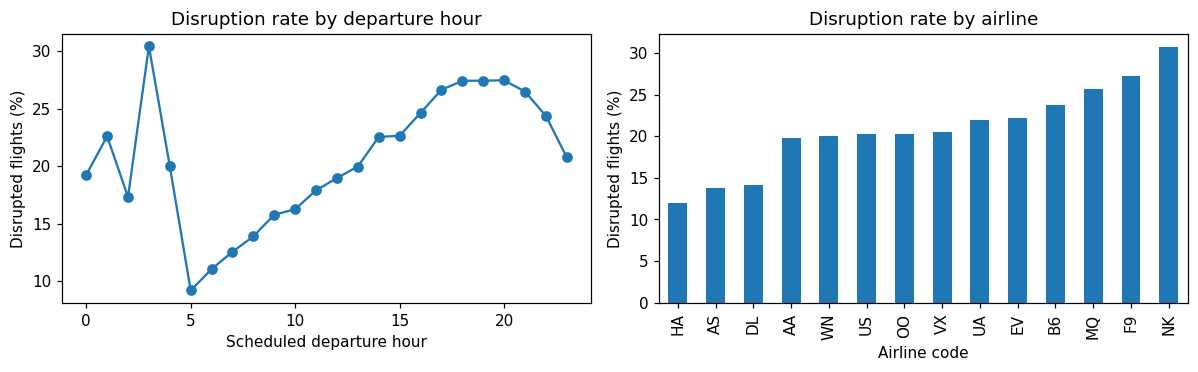

In [5]:
explore = X_train.copy()
explore['DISRUPTED'] = y_train
hour_rate = explore.groupby('DEPARTURE_HOUR')['DISRUPTED'].mean() * 100
airline_rate = explore.groupby('AIRLINE')['DISRUPTED'].mean().sort_values() * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
hour_rate.plot(ax=axes[0], marker='o', title='Disruption rate by departure hour')
airline_rate.plot.bar(ax=axes[1], title='Disruption rate by airline')
axes[0].set_xlabel('Scheduled departure hour')
axes[1].set_xlabel('Airline code')
for ax in axes:
    ax.set_ylabel('Disrupted flights (%)')
plt.tight_layout()
plt.show()
print('Highest hourly rate:', int(hour_rate.idxmax()), 'at', round(hour_rate.max(), 1), '%')
print('Lowest hourly rate:', int(hour_rate.idxmin()), 'at', round(hour_rate.min(), 1), '%')
print('Airline rate range:', round(airline_rate.min(), 1), 'to', round(airline_rate.max(), 1), '%')

The airline rates range from 11.9% to 30.8%. The highest hourly rate is at 03:00, but that hour has few observations, so it should be interpreted cautiously. The charts show where support demand may be higher. These are associations: airline differences can also reflect routes and schedules. They do not prove that the airline or departure hour caused a disruption.

## 5. Two models
**Logistic regression** learns a weighted relationship between the inputs and the chance of disruption. **Decision tree** uses a series of simple questions, such as whether departure time is later than a chosen hour. Logistic regression is a straightforward comparison; a tree can capture different patterns for different groups.

The preprocessing fills missing values, scales numeric inputs and turns airline codes into 0/1 columns. It is fitted within training so the evaluation rows do not influence it. Both models use balanced class weights because disruptions are less common than normal flights.

In [6]:
number_steps = Pipeline([('fill', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
airline_steps = Pipeline([('fill', SimpleImputer(strategy='most_frequent')), ('encode', OneHotEncoder(handle_unknown='ignore'))])
prepare = ColumnTransformer([('numbers', number_steps, numeric), ('airline', airline_steps, ['AIRLINE'])])

logistic = Pipeline([('prepare', prepare), ('model', LogisticRegression(class_weight='balanced', max_iter=500, random_state=42))])
tree = Pipeline([('prepare', prepare), ('model', DecisionTreeClassifier(class_weight='balanced', random_state=42))])

## 6. Tuning and evaluation
GridSearchCV tries three settings for each model using three training folds. For logistic regression, C controls how strongly large weights are limited. For the tree, max_depth limits the number of questions down each branch. Choose the model with the best cross-validation F1, then evaluate it once on the reserved 20%.

Precision tells us how many disruption alerts are correct. Recall tells us how many actual disruptions are found. F1 balances the two. Accuracy is included, but predicting every flight as normal could already look accurate because most flights are not disrupted.

In [7]:
logistic_search = GridSearchCV(logistic, {'model__C': [0.1, 1, 10]}, scoring='f1', cv=3)
tree_search = GridSearchCV(tree, {'model__max_depth': [3, 5, 8]}, scoring='f1', cv=3)
logistic_search.fit(X_train, y_train)
tree_search.fit(X_train, y_train)

comparison = pd.DataFrame([
    {'Model': 'Logistic regression', 'Validation F1': logistic_search.best_score_, 'Best setting': str(logistic_search.best_params_)},
    {'Model': 'Decision tree', 'Validation F1': tree_search.best_score_, 'Best setting': str(tree_search.best_params_)}
])
display(comparison.round(3))
if logistic_search.best_score_ >= tree_search.best_score_:
    best_model = logistic_search.best_estimator_
    best_name = 'Logistic regression'
else:
    best_model = tree_search.best_estimator_
    best_name = 'Decision tree'
print('Selected model:', best_name)

Selected model: Decision tree


,Model,Validation F1,Best setting
0,Logistic regression,0.370,{'model__C': 0.1}
1,Decision tree,0.381,{'model__max_depth': 8}


Always predicting normal gives accuracy: 0.8
About 27 of every 100 alerts are correct.
About 62 of every 100 actual disruptions are found.


Accuracy     0.590
Precision    0.272
Recall       0.622
F1           0.378
Name: Final evaluation, dtype: float64

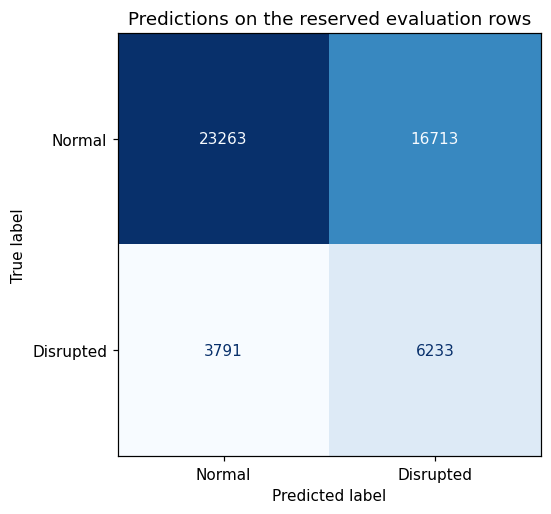

In [8]:
prediction = best_model.predict(X_test)
scores = pd.Series({
    'Accuracy': accuracy_score(y_test, prediction),
    'Precision': precision_score(y_test, prediction, zero_division=0),
    'Recall': recall_score(y_test, prediction, zero_division=0),
    'F1': f1_score(y_test, prediction, zero_division=0)
})
display(scores.round(3).rename('Final evaluation'))
print('Always predicting normal gives accuracy:', round(1 - y_test.mean(), 3))
ConfusionMatrixDisplay.from_predictions(y_test, prediction, display_labels=['Normal', 'Disrupted'], cmap='Blues', colorbar=False)
plt.title('Predictions on the reserved evaluation rows')
plt.tight_layout()
plt.show()
print(f'About {scores["Precision"] * 100:.0f} of every 100 alerts are correct.')
print(f'About {scores["Recall"] * 100:.0f} of every 100 actual disruptions are found.')

The decision tree was selected (depth 8; validation F1 0.381 versus 0.370 for logistic regression). Its final F1 is 0.378. Accuracy is lower than always predicting normal because the model finds more disruptions at the cost of false alerts. The chosen model has the higher validation F1. False alerts mean staff may review a normal flight; missed disruptions mean some passengers will still need unplanned help. Weather and current airport conditions are not included. The data comes from the US in 2015, so the model is a historical classroom example and should not be used as a current flight forecast.

## 7. Save and use the app
Save the selected model and open the simple Streamlit form. It takes the airline, month, weekday, departure hour, distance and planned duration, then displays a prediction. The app calculates the weekend feature from the weekday.

In [9]:
Path('models').mkdir(exist_ok=True)
joblib.dump(best_model, 'models/model.joblib')
print('Saved models/model.joblib')
print('Run: streamlit run app/streamlit_app.py')

Saved models/model.joblib
Run: streamlit run app/streamlit_app.py


Upload this project to [the team repository](https://github.com/Celestica19/cds4003-flight-disruption), then deploy `app/streamlit_app.py` from that repository in Streamlit Community Cloud. The [existing app](https://cds4003-flight-disruption-npatkr4rrtvz5rg79napp9q.streamlit.app/) still shows the earlier version; this simplified version has not been published.

**References:** [Kaggle dataset](https://www.kaggle.com/datasets/usdot/flight-delays); [scikit-learn user guide](https://scikit-learn.org/stable/user_guide.html); [Streamlit documentation](https://docs.streamlit.io/).

**Assistance:** ChatGPT helped prepare code and explanations. The team reported instructor approval for AI-assisted writing. Team members should understand the code and record their own actual contributions.